# 눈 자극 예측 모델 — 606행·673행 평가와 추가 자료 효과 비교

이 노트북은 **이미 완료·검증된 실험 결과**를 읽어 표와 그래프를 생성합니다. 모델 학습, 원본 변경, 최종 모델 교체는 수행하지 않습니다.

### 구분해야 할 두 비교
1. **통제실험:** 기존 606행의 평가 대상과 외부·내부 그룹 분할을 고정하고, 추가 67행을 학습에 활용/제외합니다. 6개 조합 모두 비교합니다.
2. **기존 결과 분해:** 과거606 → 새 방식의 기존606 → 새 방식의 전체673을 비교합니다. 앞 단계는 학습·분할 절차의 복합 변화이며, 뒤 단계는 같은 새 예측의 집계 대상 변경입니다.

대상: EPA I/II 양성, III/IV 음성. 3개 시드 × 외부 5폴드 / 내부 3폴드. 각 모델 20개 설정 후보. 전처리·가중치·설정·임계값은 학습 및 내부 검증에서만 결정합니다.

**실행:** 이 노트북을 결과 폴더에 둔 채 `Run All`을 실행하세요. 필요한 패키지: pandas, numpy, matplotlib, nbformat, ipykernel. 기본 경로는 현재 폴더이며, 다른 곳에서 실행하면 아래 `DATA_DIR`을 지정하세요.

In [1]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

DATA_DIR = Path.cwd()  # 노트북이 있는 통제비교 결과 폴더
NEW_DIR = DATA_DIR.parent / "최최종모델"
assert (DATA_DIR / "audit.json").is_file(), "DATA_DIR을 통제비교 결과 폴더로 지정하세요."
fonts = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if name in fonts:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 150)
print("분석 경로:", DATA_DIR)
print("Python:", platform.python_version())

분석 경로: C:\Users\DS\COS\최종\통제비교_606고정_추가67효과
Python: 3.14.6


## 1. 데이터 출처와 검증 상태
저장된 감사 기록과 파일 해시를 확인합니다. 이 셀은 이전 감사 전체를 다시 수행하는 것이 아니라, **감사를 통과한 결과 파일이 변경되지 않았는지** 확인합니다. 과거 추가자료 활용 조건은 검증된 예측 기록을 재사용했으며, 과거 모델 바이너리는 없어 재실행 검증하지 않았습니다.

In [2]:
def load_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))
def check_hash(path, expected):
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, f"파일 변경 감지: {path}"

audit = load_json(DATA_DIR / "audit.json")
receipt = load_json(DATA_DIR / "delivery_receipt.json")
assert audit["status"] == "passed" and receipt["status"] == "complete"
assert audit["identity"] == receipt["comparison_identity"]
for name, digest in audit["output_hashes"].items():
    check_hash(DATA_DIR / name, digest)
for name, digest in receipt["files"].items():
    check_hash(DATA_DIR / name, digest)
new_checksums = load_json(NEW_DIR / "checksums.json")
for name in ["metrics_by_seed.csv", "comparison_verification.json"]:
    check_hash(NEW_DIR / name, new_checksums[name])
assert load_json(NEW_DIR / "comparison_verification.json")["status"] == "passed"

metrics = pd.read_csv(DATA_DIR / "metrics_by_seed.csv")
paired = pd.read_csv(DATA_DIR / "paired_deltas.csv")
existing = pd.read_csv(DATA_DIR / "existing_protocol_metrics.csv")
settings = pd.read_csv(DATA_DIR / "selected_settings.csv")
new_metrics = pd.read_csv(NEW_DIR / "metrics_by_seed.csv")
assert len(metrics) == 72 and len(paired) == 36 and len(existing) == 144
assert metrics["rows"].eq(606).all()
assert not metrics.duplicated(["condition", "model", "representation", "seed", "rule"]).any()
display(pd.Series({"기준선 외부 폴드": audit["baseline_outer"], "신규 외부 폴드": audit["noadd_outer"],
                   "paired OOF 기록": audit["oof_rows"], "신규 모델 예측 재구성": audit["noadd_model_reconstruction"],
                   "과거 모델 자체 재구성": audit["historical_model_reconstruction"]}, name="검증 범위").to_frame())

,검증 범위
기준선 외부 폴드,90
신규 외부 폴드,90
paired OOF 기록,21816
신규 모델 예측 재구성,True
과거 모델 자체 재구성,False


In [3]:
model_names = {"lr": "LR", "rf": "Random Forest", "xgb": "XGBoost"}
rep_names = {"wmean": "가중평균", "max": "최댓값"}
condition_names = {"noaugmentation": "추가67 제외", "augmented": "추가67 활용"}
order = [f"{model_names[m]} · {rep_names[r]}" for m in ["lr", "rf", "xgb"] for r in ["wmean", "max"]]
measures = ["sensitivity", "specificity", "MCC", "ROC-AUC"]
metric_names = {"sensitivity": "민감도", "specificity": "특이도", "MCC": "MCC", "ROC-AUC": "AUC"}
for frame in [metrics, paired, existing, settings, new_metrics]:
    frame["조합"] = frame["model"].map(model_names) + " · " + frame["representation"].map(rep_names)

def show(frame):
    display(frame.style.format(precision=4))

## 2. 전체 673행 평가: 6개 모델·집계 조합
각 조합에 같은 그룹 분할을 적용한 새 실험입니다. 아래 값은 **시드별 전체 OOF 지표의 평균**입니다. AUC는 폴드 AUC 평균이 아니라 시드 내 OOF 점수를 합친 AUC입니다. 순위는 MCC 기준이며 AUC만 보면 순위가 다를 수 있습니다.

,민감도,특이도,MCC,AUC
조합,,,,
LR · 가중평균,0.6907,0.6782,0.2943,0.7161
LR · 최댓값,0.6480,0.6800,0.2628,0.7213
XGBoost · 가중평균,0.6613,0.6411,0.2391,0.6821
Random Forest · 가중평균,0.6347,0.6618,0.2361,0.6958
Random Forest · 최댓값,0.6187,0.6606,0.2228,0.6765
XGBoost · 최댓값,0.6533,0.6235,0.2193,0.6761


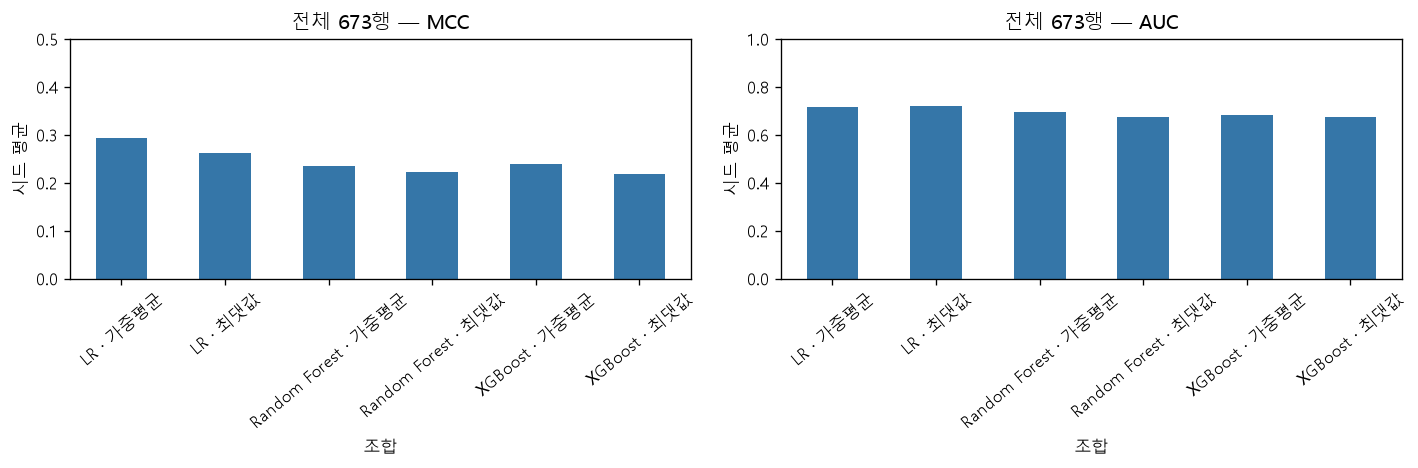

In [4]:
all673 = new_metrics[new_metrics["subgroup"].eq("overall")]
assert len(all673) == 18 and all673["rows"].eq(673).all()
all_mean = all673.groupby("조합")[measures].mean().reindex(order)
show(all_mean.sort_values("MCC", ascending=False).rename(columns=metric_names))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["MCC", "ROC-AUC"]):
    all_mean[metric].plot.bar(ax=ax, color="#3576a8")
    ax.set_title(f"전체 673행 — {metric_names[metric]}")
    ax.set_ylabel("시드 평균")
    ax.tick_params(axis="x", rotation=40)
    ax.set_ylim(0, 1 if metric == "ROC-AUC" else 0.5)
plt.tight_layout()
plt.show()

## 3. 핵심 통제실험: 같은 606행·같은 분할에서 추가 자료 활용/제외
각 조건에서 설정과 임계값을 내부 검증으로 다시 선택합니다. 따라서 비교값은 **추가 자료 정책에 따른 모델 적합·클래스 가중치·튜닝의 반응을 포함한 효과**입니다. 라벨 오류의 증거나 새673 분할 효과의 단독 추정은 아닙니다.

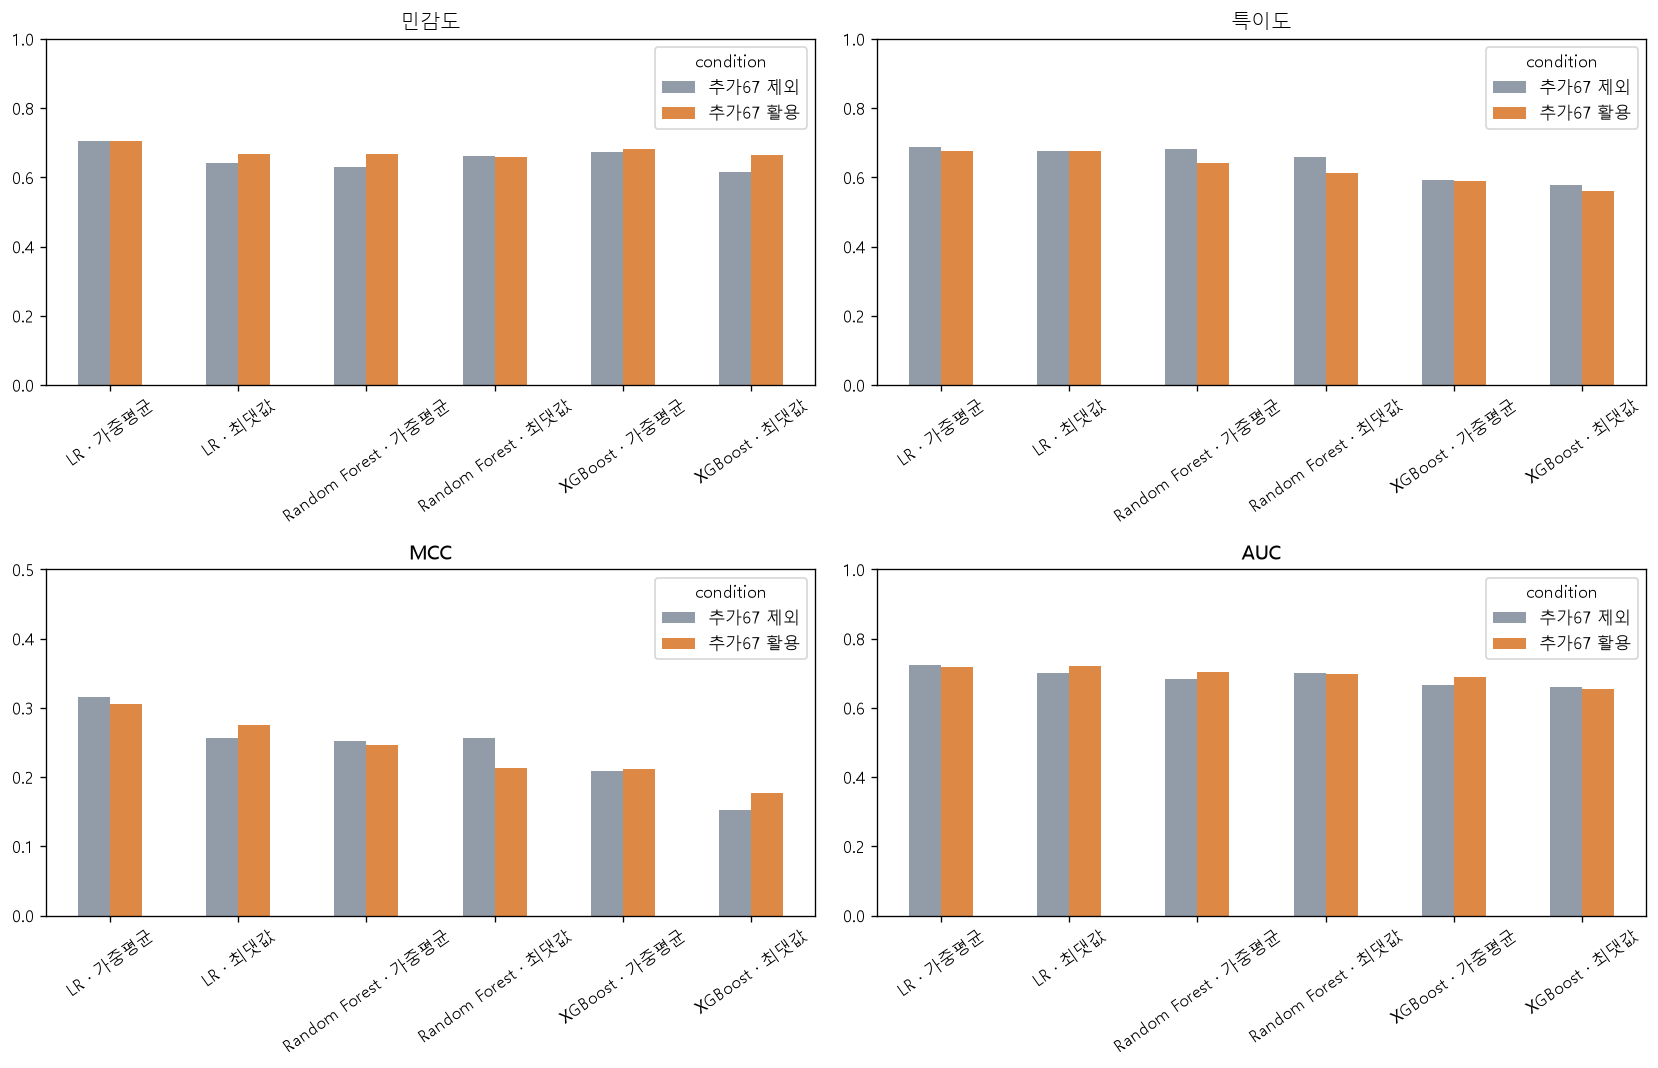

In [5]:
tuned = metrics[metrics["rule"].eq("tuned")]
means = tuned.groupby(["조합", "condition"])[measures].mean()
show(means.rename(index=condition_names, level="condition").rename(columns=metric_names))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, metric in zip(axes.flat, measures):
    table = means[metric].unstack("condition").reindex(order)[["noaugmentation", "augmented"]]
    table.rename(columns=condition_names).plot.bar(ax=ax, color=["#919ca8", "#dd8844"])
    ax.set_title(metric_names[metric]); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35)
    ax.set_ylim(0, 1 if metric != "MCC" else 0.5)
plt.tight_layout(); plt.show()

## 4. 추가 자료의 효과: 시드별 짝지은 차이
**차이 = 추가67 활용 − 제외.** MCC·AUC에서 양수면 활용 조건이 높고 음수면 제외 조건이 높습니다. 점은 각 시드의 차이, 검은 마름모는 평균입니다. 세 시드는 같은 자료를 반복 사용하므로 독립 표본이나 신뢰구간으로 해석하지 않습니다.

,민감도,특이도,MCC,AUC
조합,,,,
LR · 가중평균,0.0000,-0.0109,-0.0101,-0.0061
LR · 최댓값,0.0261,-0.0007,0.0194,0.0186
Random Forest · 가중평균,0.0377,-0.0407,-0.0068,0.0193
Random Forest · 최댓값,-0.0029,-0.0468,-0.0426,-0.0019
XGBoost · 가중평균,0.0087,-0.0048,0.0028,0.0223
XGBoost · 최댓값,0.0493,-0.0163,0.0254,-0.0058


C:\Users\DS\AppData\Local\Temp\ipykernel_21808\3616135260.py:17: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout(); plt.show()


C:\Users\DS\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


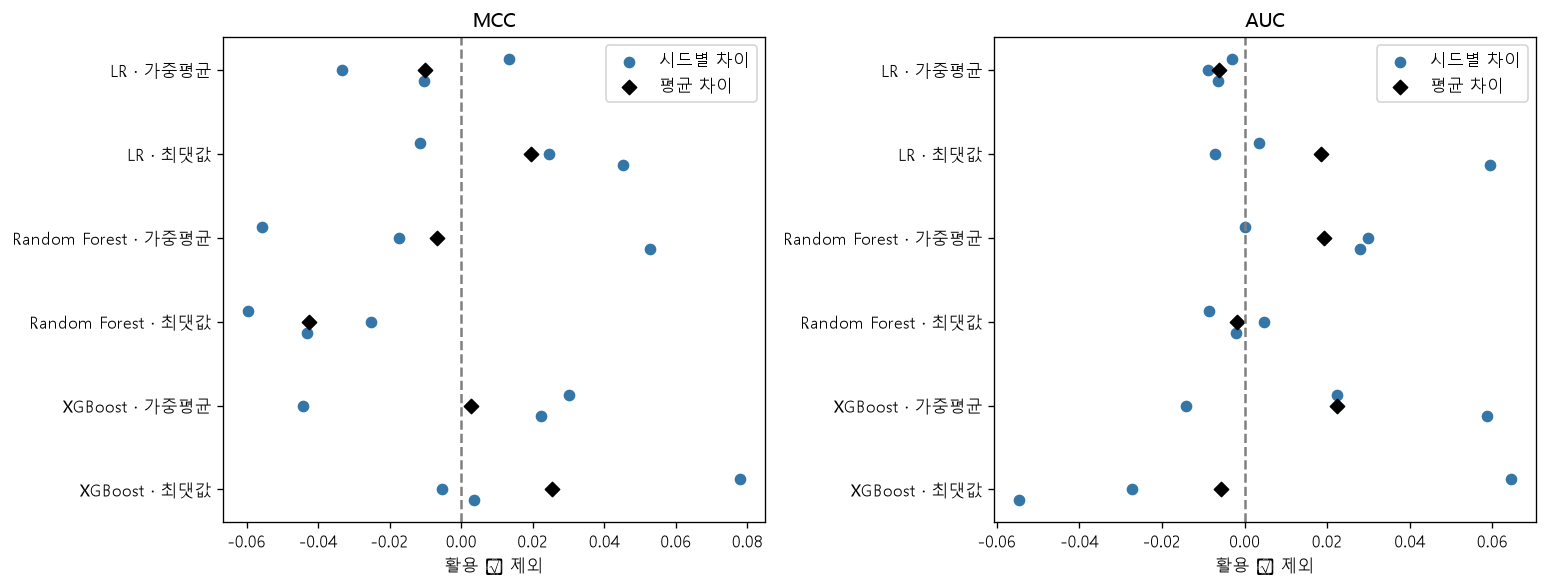

In [6]:
keys = ["model", "representation", "seed", "rule"]
a = metrics[metrics.condition.eq("augmented")].set_index(keys)[measures]
b = metrics[metrics.condition.eq("noaugmentation")].set_index(keys)[measures]
expected = (a - b).sort_index()
np.testing.assert_allclose(paired.set_index(keys)[measures].sort_index(), expected, atol=1e-12, rtol=0)
pt = paired[paired.rule.eq("tuned")]
show(pt.groupby("조합")[measures].mean().reindex(order).rename(columns=metric_names))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric in zip(axes, ["MCC", "ROC-AUC"]):
    for i, combo in enumerate(order):
        values = pt[pt["조합"].eq(combo)].sort_values("seed")[metric].to_numpy()
        ax.scatter(values, i + np.array([-0.13, 0, 0.13]), color="#3576a8", label="시드별 차이" if i == 0 else None)
        ax.scatter(values.mean(), i, marker="D", color="black", label="평균 차이" if i == 0 else None)
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(range(len(order)), order); ax.invert_yaxis()
    ax.set_xlabel("활용 − 제외"); ax.set_title(metric_names[metric]); ax.legend()
plt.tight_layout(); plt.show()

## 5. 임계값 영향: 내부 검증 임계값 vs 고정 0.5
0.5는 비교 진단용으로 사전에 정한 값입니다. 평가 결과를 보고 최적 임계값을 찾는 셀이 아니며, 서비스 임계값 변경을 권고하지 않습니다. 동일 점수의 AUC는 두 판정 규칙에서 같아야 합니다.

C:\Users\DS\AppData\Local\Temp\ipykernel_21808\4098232333.py:9: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.xticks(rotation=35); plt.tight_layout(); plt.show()
C:\Users\DS\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


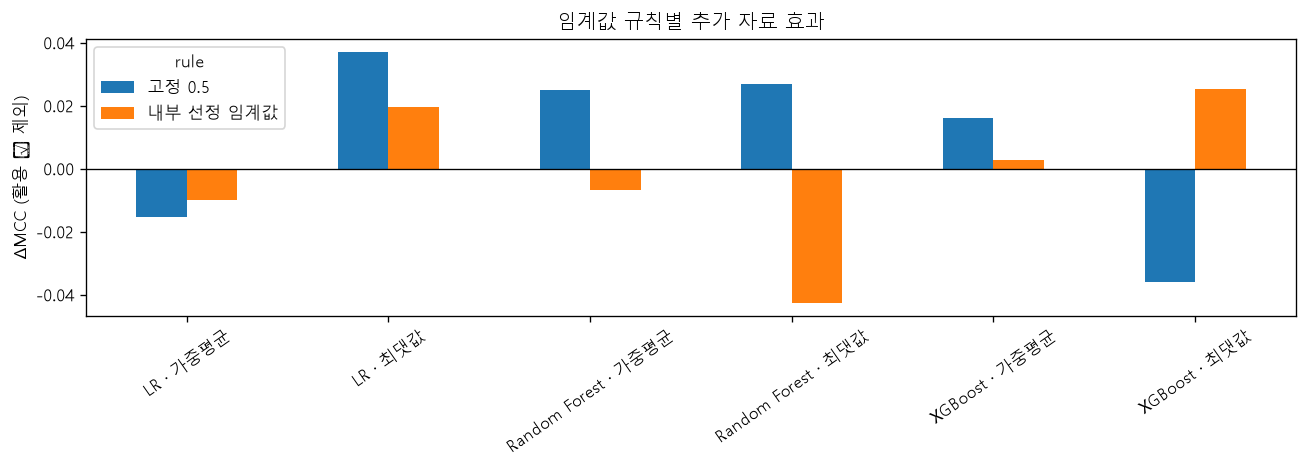

In [7]:
auc_rules = metrics.pivot(index=["condition", "model", "representation", "seed"], columns="rule", values="ROC-AUC")
np.testing.assert_allclose(auc_rules["tuned"], auc_rules["fixed0.5"], atol=1e-12, rtol=0)
lr = metrics[metrics.model.eq("lr") & metrics.representation.eq("wmean")]
show(lr.groupby(["condition", "rule"])[measures].mean().rename(index=condition_names, level="condition").rename(columns=metric_names))
delta_rules = paired.groupby(["조합", "rule"])["MCC"].mean().unstack().reindex(order)
ax = delta_rules.rename(columns={"tuned": "내부 선정 임계값", "fixed0.5": "고정 0.5"}).plot.bar(figsize=(11, 4))
ax.axhline(0, color="black", linewidth=0.8); ax.set_ylabel("ΔMCC (활용 − 제외)")
ax.set_title("임계값 규칙별 추가 자료 효과"); ax.set_xlabel("")
plt.xticks(rotation=35); plt.tight_layout(); plt.show()
show(settings.groupby(["조합", "condition"])["threshold"].agg(["mean", "min", "max"]).reindex(order, level="조합").rename(index=condition_names, level="condition"))

## 6. 왜 606→673행 보고 성능이 낮아졌는가?
- **A → B:** 평가 대상은 기존606으로 같지만 학습·그룹 분할·폴드별 학습량·내부 선정 자료가 달라집니다. 여러 요인이 섞인 관찰 비교입니다.
- **B → C:** 새 모델의 예측을 그대로 두고 보고 대상만 기존606에서 전체673으로 넓힙니다.
- 과거 실험도 추가67을 학습에 활용했습니다. 따라서 통제실험의 '추가자료 활용 효과'를 과거→현재 하락의 원인 전체로 간주하면 안 됩니다.

아래는 LR·가중평균입니다. 다른 조합의 값도 표에서 확인할 수 있습니다.

,민감도,특이도,MCC,AUC
condition,,,,
A. 과거 방식·606평가,0.7043,0.6775,0.3063,0.7189
B. 새 방식·기존606,0.6638,0.6965,0.2926,0.7123
C. 새 방식·전체673,0.6907,0.6782,0.2943,0.7161


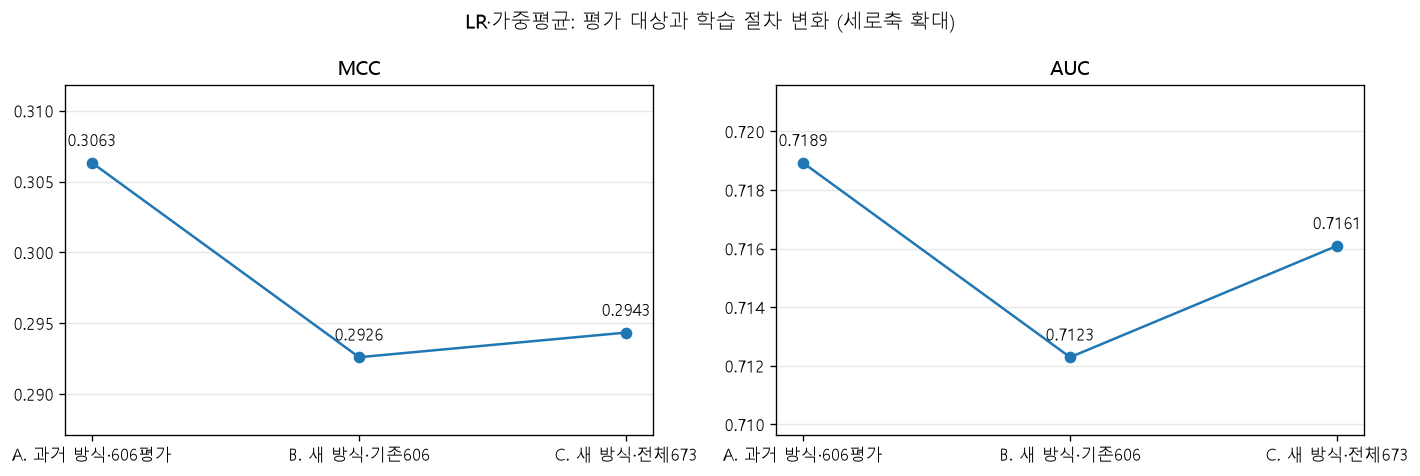

In [8]:
stages = ["old_augmented_eval606", "new_protocol_eval606", "new_protocol_eval673"]
labels = {stages[0]: "A. 과거 방식·606평가", stages[1]: "B. 새 방식·기존606", stages[2]: "C. 새 방식·전체673"}
et = existing[existing.decision_rule.eq("tuned") & existing.condition.isin(stages)]
trajectory = et.groupby(["조합", "condition"])[measures].mean()
lr_path = trajectory.loc["LR · 가중평균"].reindex(stages)
show(lr_path.rename(index=labels, columns=metric_names))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["MCC", "ROC-AUC"]):
    values = lr_path[metric]
    ax.plot(range(3), values, marker="o")
    for i, value in enumerate(values): ax.annotate(f"{value:.4f}", (i, value), xytext=(0, 10), textcoords="offset points", ha="center")
    ax.set_xticks(range(3), [labels[s] for s in stages]); ax.set_title(metric_names[metric])
    ax.margins(y=0.4); ax.grid(axis="y", alpha=0.3)
plt.suptitle("LR·가중평균: 평가 대상과 학습 절차 변화 (세로축 확대)")
plt.tight_layout(); plt.show()
contrasts = []
for combo in order:
    block = trajectory.loc[combo]
    for name, after, before in [("A→B: 학습/분할 복합 변화", stages[1], stages[0]), ("B→C: 집계 대상 변화", stages[2], stages[1])]:
        contrasts.append({"조합": combo, "비교": name, **(block.loc[after] - block.loc[before]).to_dict()})
show(pd.DataFrame(contrasts).set_index(["조합", "비교"]).rename(columns=metric_names))

## 7. 데이터에서 계산한 요약과 해석 한계

In [9]:
lr_delta = pt[pt.model.eq("lr") & pt.representation.eq("wmean")][measures].mean()
fixed_delta = paired[paired.model.eq("lr") & paired.representation.eq("wmean") & paired.rule.eq("fixed0.5")]["MCC"].mean()
population = lr_path.loc[stages[2]] - lr_path.loc[stages[1]]
print(f"LR·가중평균: 추가67 활용−제외 ΔMCC={lr_delta['MCC']:+.6f}, ΔAUC={lr_delta['ROC-AUC']:+.6f}")
print(f"고정0.5에서도 ΔMCC={fixed_delta:+.6f}")
print(f"새 예측에서 평가 집계만 606→673: ΔMCC={population['MCC']:+.6f}, ΔAUC={population['ROC-AUC']:+.6f}")
print("모든 파일 검증 및 표 계산 완료. 학습 실행 또는 최종 모델 변경 없음.")

LR·가중평균: 추가67 활용−제외 ΔMCC=-0.010095, ΔAUC=-0.006134
고정0.5에서도 ΔMCC=-0.015392
새 예측에서 평가 집계만 606→673: ΔMCC=+0.001741, ΔAUC=+0.003804
모든 파일 검증 및 표 계산 완료. 학습 실행 또는 최종 모델 변경 없음.


### 결론
- **LR·가중평균의 고정606 통제실험에서는 추가67 활용이 평균 MCC·AUC에 소폭 불리했습니다.** 하지만 다른 모델·집계 방식에서는 도움이 되기도 합니다.
- LR·가중평균에서 새 예측의 집계 대상을 606→673으로 넓히면 MCC·AUC는 오히려 높아집니다. 따라서 기존→현재 하락을 '추가67을 평가해서'라고 설명할 수 없습니다.
- 같은 606행에서 새 학습·분할 절차의 성능이 낮아진 것은 관찰되지만, 분할·학습량·튜닝의 개별 기여를 이 실험으로 모두 분리한 것은 아닙니다.
- 추가 자료의 라벨이 잘못됐다는 증거도 아닙니다. 출처·라벨 일관성·성분 표현·목표 사용집단 적합성을 별도로 검토해야 합니다.
- 세 시드의 차이는 기술통계이며 통계적 유의성이나 외부 일반화 성능을 확정하지 않습니다. 전체673 비교에서 선택한 우승 모델의 같은 성능치에는 선택 편향이 있을 수 있습니다.
- 기존 최종 모델과 원본 실험 결과는 보존됩니다. 자세한 설명은 `INTERPRETATION.txt`, 감사 기록은 `audit.json`을 참고하세요.

### 재현 정보
이 노트북은 표·그림만 메모리에서 생성합니다. 새로운 결과로 바꾸려면 숫자를 직접 수정하지 말고 해당 실험의 결과와 감사 파일을 함께 갱신해야 합니다. 원본 결과가 바뀌면 해시 검증이 실패하도록 구성했습니다.